# 01 · Exploratory analysis: bank account opening fraud

**Dataset.** The *Bank Account Fraud* (BAF) suite, published by Feedzai at NeurIPS 2022:
1 million applications to open a bank account online, over 8 months, 1.1 % of them
fraudulent. It is **synthetic**: a generative model was trained on a real anonymised
dataset and then sampled, so no real customer appears, while the statistical structure,
including its biases, is kept. That makes it one of the few public fraud datasets where
**fairness** can be studied, because it contains protected attributes such as age.

**What account-opening fraud is.** A fraudster opens an account with a stolen or
synthetic identity, then uses it to receive stolen money (a "mule" account) or to max out
credit and disappear. The bank sees only the application: who you say you are, how you
applied, and from which device.

**Why this dataset is in the portfolio.** Projects 1–2 asked "how much fraud can we
catch?". This one adds two questions that come up in a real deployment:
1. The business fixes the share of **legitimate applicants it is willing to reject**
   (here 5 %). How much fraud is caught at that operating point, and does it hold up as
   the data shifts month to month?
2. **Who bears the errors?** Are legitimate applicants from some groups wrongly rejected
   more often than others?

The suite has a base dataset and five variants with deliberately injected biases. We use
**Base**.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp, spearmanr

from fraudkit import baf
from fraudkit.metrics import wilson_interval
from fraudkit.plotting import (
    CLASS_COLORS, INK_2, MUTED, SERIES, class_legend, finish, label_bars, set_style,
)

set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.4f}".format)

df = baf.load()   # as published, but missing-value sentinels → NaN and an age_group column added
print(f"{len(df):,} applications × {df.shape[1]} columns, {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
print(f"fraud rate: {df.fraud_bool.mean():.2%}")
df.head()

1,000,000 applications × 33 columns, 97 MB
fraud rate: 1.10%


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month,age_group
0,0,0.3000,0.9865,NaN,25.0000,40.0000,0.0067,102.4537,AA,"1,059.0000",...,"1,500.0000",0,INTERNET,16.2248,linux,1,1.0000,0,0,<50
1,0,0.8000,0.6174,NaN,89.0000,20.0000,0.0101,NaN,AD,"1,658.0000",...,"1,500.0000",0,INTERNET,3.3639,other,1,1.0000,0,0,<50
2,0,0.8000,0.9967,9.0000,14.0000,40.0000,0.0123,NaN,AB,"1,095.0000",...,200.0000,0,INTERNET,22.7306,windows,0,1.0000,0,0,<50
3,0,0.6000,0.4751,11.0000,14.0000,30.0000,0.0070,NaN,AB,"3,483.0000",...,200.0000,0,INTERNET,15.2158,linux,1,1.0000,0,0,<50
4,0,0.9000,0.8423,NaN,29.0000,40.0000,5.7426,47.1525,AA,"2,339.0000",...,200.0000,0,INTERNET,3.7430,other,0,1.0000,0,0,<50


Columns, grouped (full definitions in the dataset's datasheet):

| Group | Examples |
|---|---|
| Applicant | `income` (decile), `customer_age` (decade), `employment_status`, `housing_status` |
| Identity checks | `name_email_similarity`, `email_is_free`, `phone_home_valid`, `phone_mobile_valid`, `date_of_birth_distinct_emails_4w` |
| Address & history | `prev_address_months_count`, `current_address_months_count`, `bank_months_count`, `has_other_cards` |
| Application | `payment_type`, `intended_balcon_amount`, `proposed_credit_limit`, `credit_risk_score`, `source` (internet or phone) |
| Velocity | applications in the last 6 h / 24 h / 4 weeks (`velocity_*`), from the same branch or zip code |
| Session & device | `session_length_in_minutes`, `device_os`, `keep_alive_session`, `device_distinct_emails_8w`, `foreign_request` |

Categorical values are anonymised codes (e.g. employment status `CA`…`CG`).

## 1. Time: eight months, rising fraud

The standard protocol for BAF is to train on months 0–5 and test on months 6–7.

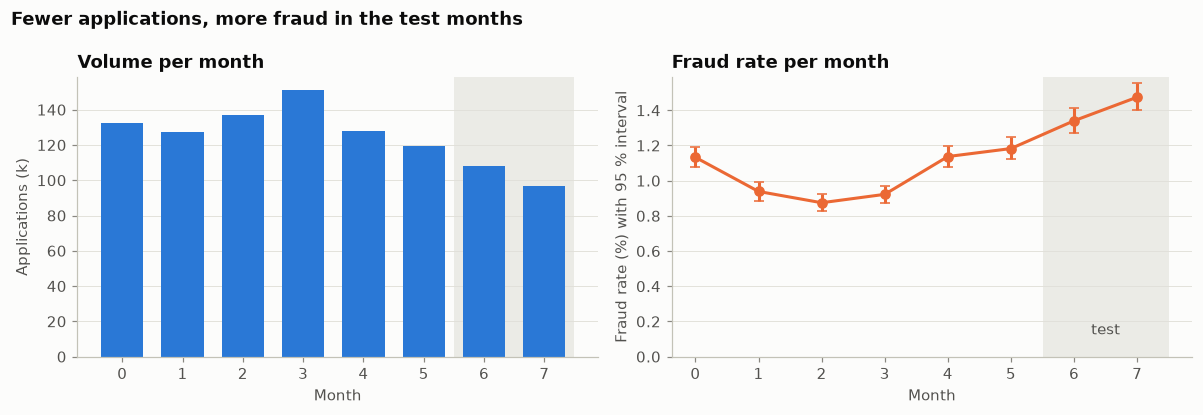

In [2]:
monthly = df.groupby("month").fraud_bool.agg(n="size", frauds="sum")
monthly["rate"] = monthly.frauds / monthly.n
lo, hi = wilson_interval(monthly.frauds, monthly.n)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.bar(monthly.index, monthly.n / 1000, color=SERIES[0], width=0.7)
ax1.set_ylabel("Applications (k)"); ax1.set_title("Volume per month")
ax2.errorbar(monthly.index, monthly.rate * 100, yerr=[(monthly.rate - lo) * 100, (hi - monthly.rate) * 100],
             color=CLASS_COLORS[1], marker="o", capsize=3, lw=2)
ax2.set_ylabel("Fraud rate (%) with 95 % interval"); ax2.set_title("Fraud rate per month")
ax2.set_ylim(0, None)
for ax in (ax1, ax2):
    ax.axvspan(5.5, 7.5, color="#e1e0d9", alpha=0.6, lw=0, zorder=0)
    ax.set_xlabel("Month"); ax.set_xticks(range(8)); ax.grid(axis="x", visible=False)
ax2.text(6.5, ax2.get_ylim()[1] * 0.08, "test", ha="center", color=INK_2)
fig.suptitle("Fewer applications, more fraud in the test months", x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.** Volume falls towards the end, while the fraud rate climbs from ~0.9 % in
months 2–3 to ~1.5 % in month 7. A model trained on months 0–5 will meet **more fraud
than it ever saw**. That matters little for ranking, but it shifts every
threshold-based metric (notebook 02).

## 2. Missing values hide behind negative numbers

The datasheet encodes "missing" as −1 (or any negative value) in several columns. Left
as is, −1 would look like a real number of months to a linear model. `baf.load` turns them
into `NaN`. Whether a value is missing can itself carry signal:

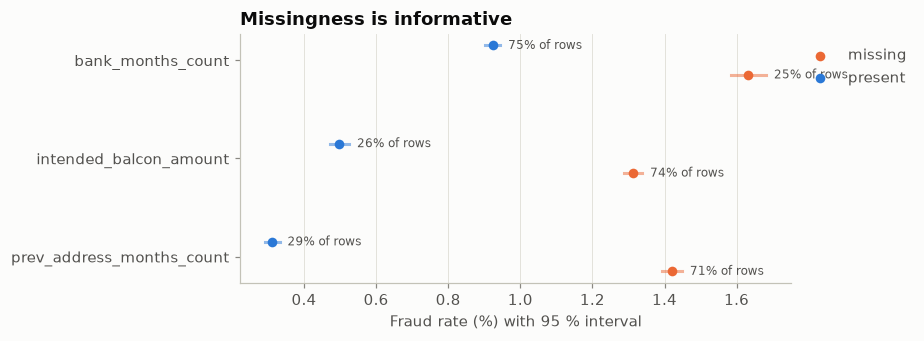

In [3]:
rows = []
for c in baf.MISSING_IF_NEGATIVE:
    m = df[c].isna()
    if m.mean() < 0.01:   # nearly complete columns: too few missing rows to say anything
        continue
    for label, mask in [("missing", m), ("present", ~m)]:
        f, n = df.fraud_bool[mask].sum(), mask.sum()
        l, h = wilson_interval(f, n)
        rows.append({"column": c, "state": label, "share": n / len(df), "rate": f / n, "lo": l, "hi": h})
miss = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.5, 3.2))
cols = miss.column.unique()
for i, c in enumerate(cols):
    for state, color, off in [("missing", SERIES[1], -0.15), ("present", SERIES[0], 0.15)]:
        r = miss[(miss.column == c) & (miss.state == state)].iloc[0]
        ax.plot([r.lo * 100, r.hi * 100], [i + off] * 2, color=color, lw=2, alpha=0.5)
        ax.scatter(r.rate * 100, i + off, color=color, s=40, zorder=3,
                   label=state if i == 0 else None)
        ax.annotate(f"{r.share:.0%} of rows", (r.hi * 100, i + off), xytext=(5, 0),
                    textcoords="offset points", va="center", fontsize=8, color=INK_2)
ax.set_yticks(range(len(cols)), cols)
ax.set_xlabel("Fraud rate (%) with 95 % interval")
ax.set_title("Missingness is informative")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.grid(axis="y", visible=False)
finish(fig)

Three columns have a substantial share missing (the other three listed in the datasheet
are over 99 % complete).

**Reading it.** All three missing patterns are riskier than having a value: no **bank
relationship history** (`bank_months_count`: 1.6 % vs 0.9 %), no stated **initial
deposit** (`intended_balcon_amount`: 1.3 % vs 0.5 %) and no **previous address** on
record (1.4 % vs 0.3 %). An applicant with little verifiable history is riskier. Trees
can learn these patterns from `NaN` directly. For a linear model we add
explicit missing-value indicators (notebook 02).

## 3. Which numeric features separate fraud?

As in project 1, a two-sample Kolmogorov–Smirnov statistic per feature: the largest gap
between the fraud and legit cumulative distributions (0 = identical, 1 = perfectly
separated).

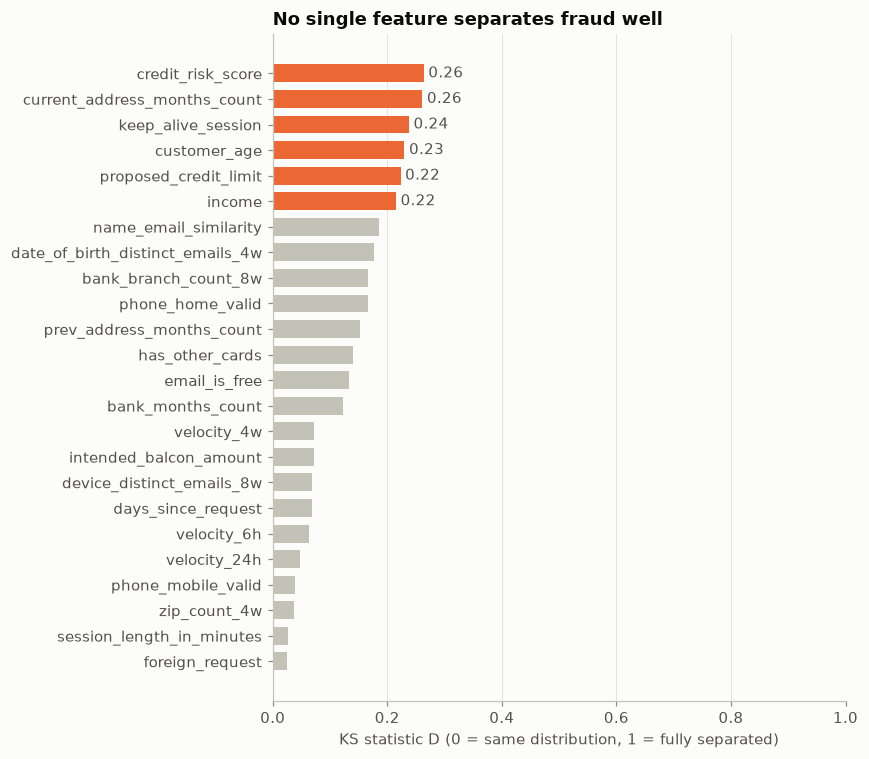

In [4]:
num_cols = [c for c in baf.features(df) if df[c].dtype != "category"]
fraud, legit = df[df.fraud_bool == 1], df[df.fraud_bool == 0]
ks = pd.Series({c: ks_2samp(fraud[c].dropna(), legit[c].dropna()).statistic for c in num_cols}).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
top = set(ks.index[-6:])
bars = ax.barh(ks.index, ks.values, height=0.7,
               color=[SERIES[1] if c in top else "#c3c2b7" for c in ks.index])
label_bars(ax, bars[-6:], fmt="{:.2f}", horizontal=True)
ax.set_xlabel("KS statistic D (0 = same distribution, 1 = fully separated)")
ax.set_title("No single feature separates fraud well")
ax.grid(axis="y", visible=False); ax.set_xlim(0, 1)
finish(fig)

**Reading it.** The best single feature reaches only *D* ≈ 0.26, far below project 1's
0.84. Application fraud is subtle: each signal is weak, so the model has to combine many
of them. The leaders are the **credit risk score**, **how long the applicant has lived at
their address**, whether the **session was kept alive**, **age**, the **proposed credit
limit** and **income**. Close behind: the **similarity between name and e-mail**
(fraudsters' e-mails rarely match the stolen name) and a **valid home phone**.

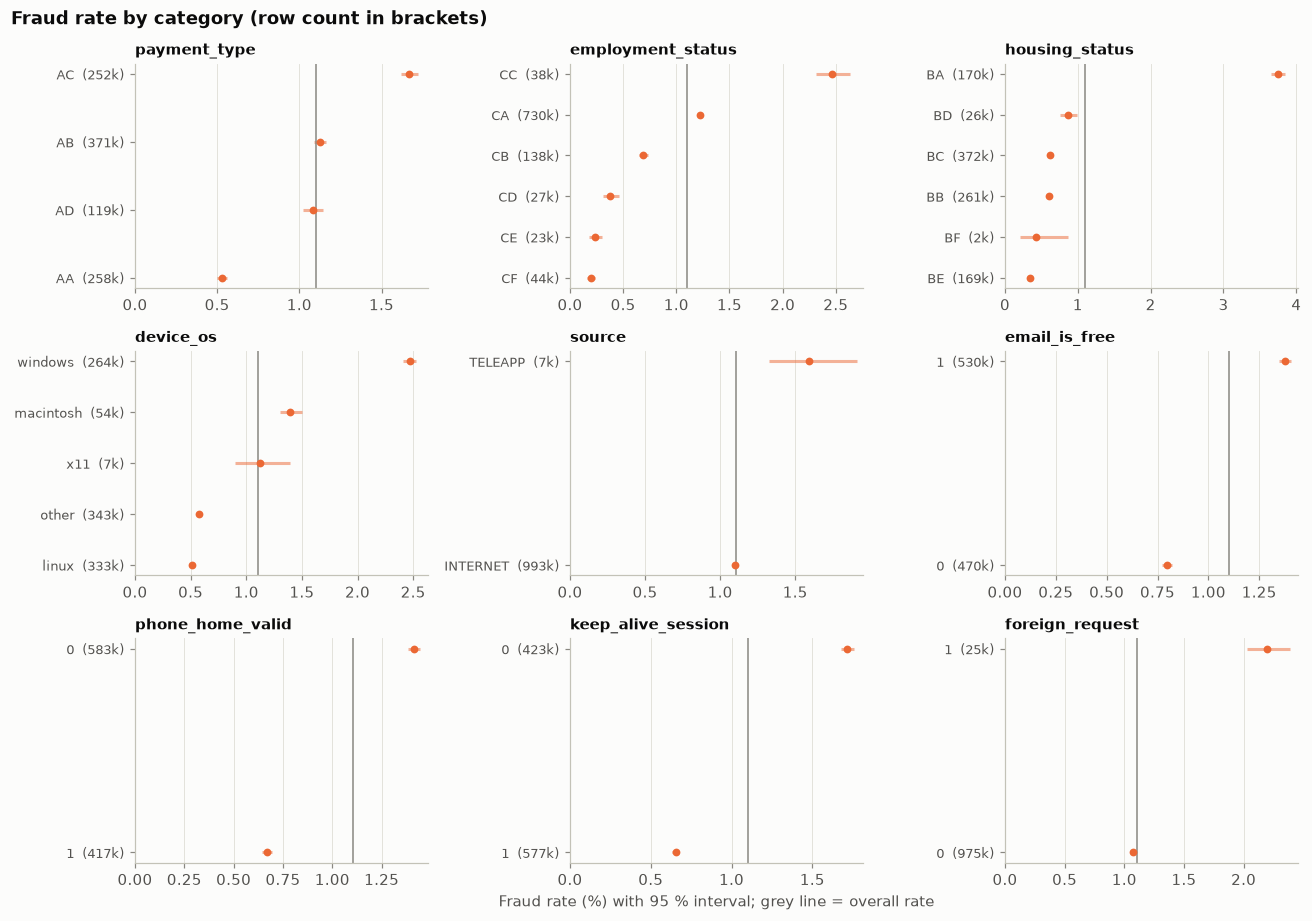

In [5]:
cat_cols = ["payment_type", "employment_status", "housing_status", "device_os", "source", "email_is_free",
            "phone_home_valid", "keep_alive_session", "foreign_request"]
fig, axes = plt.subplots(3, 3, figsize=(12, 8.5))
overall = df.fraud_bool.mean()
for ax, c in zip(axes.flat, cat_cols):
    t = df.groupby(c, observed=True).fraud_bool.agg(n="size", frauds="sum")
    t = t[t.n >= 1000]
    t["rate"] = t.frauds / t.n
    t["lo"], t["hi"] = wilson_interval(t.frauds, t.n)
    t = t.sort_values("rate")
    yy = np.arange(len(t))
    ax.hlines(yy, t.lo * 100, t.hi * 100, color=SERIES[1], lw=2, alpha=0.5)
    ax.scatter(t.rate * 100, yy, color=SERIES[1], s=26, zorder=3)
    ax.axvline(overall * 100, color=MUTED, lw=1)
    ax.set_yticks(yy, [f"{i}  ({n / 1000:,.0f}k)" for i, n in zip(t.index, t.n)], fontsize=8.5)
    ax.set_title(c, fontsize=10); ax.set_xlim(left=0); ax.grid(axis="y", visible=False)
axes[2, 1].set_xlabel("Fraud rate (%) with 95 % interval; grey line = overall rate")
fig.suptitle("Fraud rate by category (row count in brackets)", x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.** Housing status `BA` has more than three times the base rate (3.7 %), and
employment status `CC` more than double. Applications from **Windows** devices, with a
**free e-mail** address, from **abroad** or by **phone** (`TELEAPP`) are riskier, while a
valid home phone or a kept-alive session is reassuring. Again, many moderate signals
rather than one strong one.

## 4. Protected attributes: age and income

`customer_age` (in decades) and `income` (in deciles) describe *who* the applicant is.
Using them for decisions can be unlawful or unfair depending on jurisdiction and context.
Before any model, look at how fraud prevalence varies across these groups.

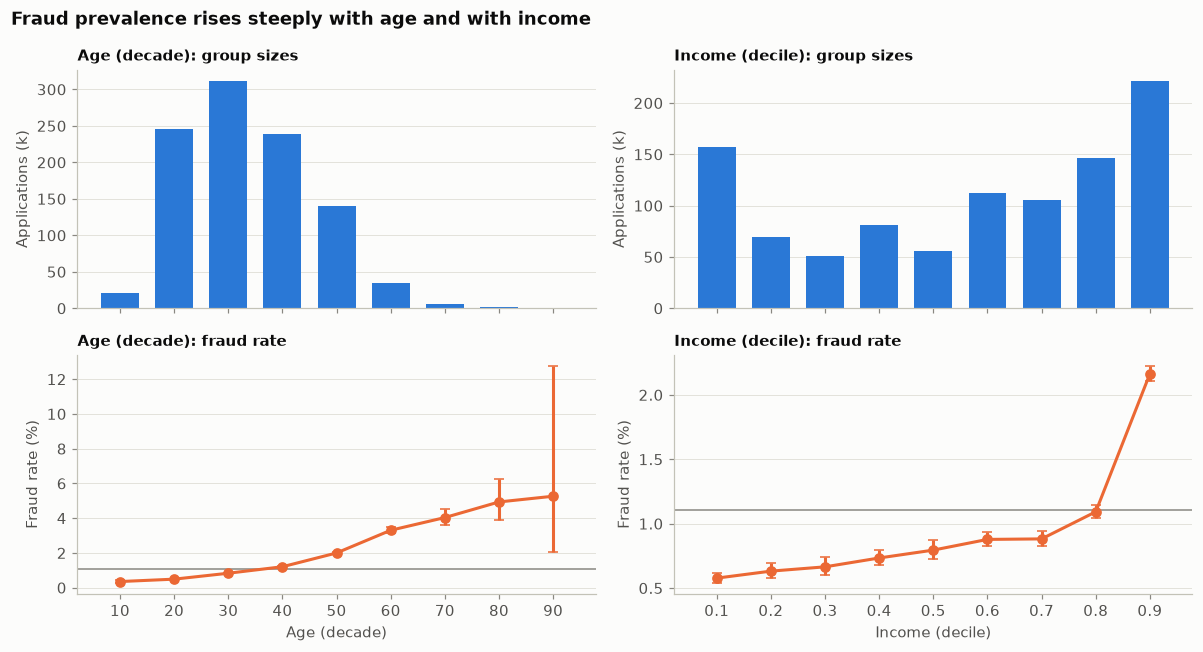

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex="col")
for j, (col, label) in enumerate([("customer_age", "Age (decade)"), ("income", "Income (decile)")]):
    t = df.groupby(col).fraud_bool.agg(n="size", frauds="sum")
    t["rate"] = t.frauds / t.n
    t["lo"], t["hi"] = wilson_interval(t.frauds, t.n)
    x = np.arange(len(t))
    axes[0, j].bar(x, t.n / 1000, color=SERIES[0], width=0.7)
    axes[0, j].set_ylabel("Applications (k)")
    axes[0, j].set_title(f"{label}: group sizes", fontsize=10)
    axes[1, j].errorbar(x, t.rate * 100, yerr=[(t.rate - t.lo) * 100, (t.hi - t.rate) * 100],
                        color=CLASS_COLORS[1], marker="o", capsize=3, lw=2)
    axes[1, j].axhline(overall * 100, color=MUTED, lw=1)
    axes[1, j].set_ylabel("Fraud rate (%)")
    axes[1, j].set_title(f"{label}: fraud rate", fontsize=10)
    axes[1, j].set_xticks(x, [f"{v:g}" for v in t.index])
    axes[1, j].set_xlabel(label)
    for a in axes[:, j]:
        a.grid(axis="x", visible=False)
fig.suptitle("Fraud prevalence rises steeply with age and with income", x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.** Applicants in their 50s are fraudulent ~2 % of the time, those in their
60s ~3 %, and those in their 80s ~5 %, against 0.5 % in their 20s. The highest income
decile is also about twice the average. Older, wealthier identities are attractive
to fraudsters, presumably because they come with better credit.

This **prevalence disparity** is the root of the fairness question in notebook 03. A model
that learns "older applicants are riskier" will be statistically right on average, and
will also wrongly reject *legitimate* older applicants more often. Note the group sizes:
the 50+ group is 18 % of applicants, while 70+ is under 1 %, too small for reliable
per-decade estimates.

### Is age hiding in other columns?

Removing `customer_age` from a model doesn't remove age from the data if other features
correlate with it. The Spearman rank correlation with age, for every numeric feature:

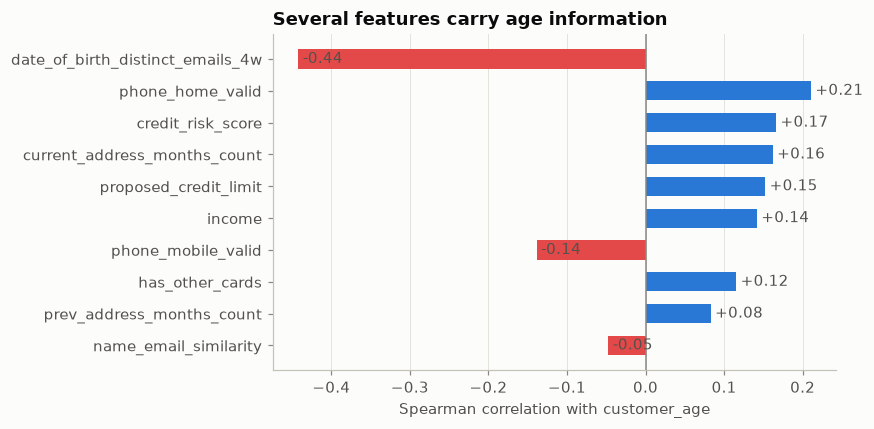

In [7]:
corr = pd.Series({c: spearmanr(df[c], df.customer_age, nan_policy="omit")[0]
                  for c in num_cols if c != "customer_age"}).dropna()
top_corr = corr.reindex(corr.abs().sort_values().index)[-10:]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(top_corr.index, top_corr.values, height=0.6,
               color=[SERIES[0] if v > 0 else SERIES[7] for v in top_corr.values])
label_bars(ax, bars, fmt="{:+.2f}", horizontal=True)
ax.axvline(0, color=MUTED, lw=1)
ax.set_xlabel("Spearman correlation with customer_age")
ax.set_title("Several features carry age information")
ax.grid(axis="y", visible=False)
finish(fig)

**Reading it.** No feature is a perfect stand-in for age, but several correlate with it:
most strongly `date_of_birth_distinct_emails_4w` (how many e-mail addresses were used
with the same date of birth in the last 4 weeks, −0.44), then a valid home phone, the
credit risk score, time at the current address and the proposed credit limit. Together they can partly
reconstruct it. Notebook 03 measures how well.

## 5. Drift between the training and test months

Which features change most between months 0–5 and 6–7? Same KS statistic, this time
comparing the two periods instead of the two classes.

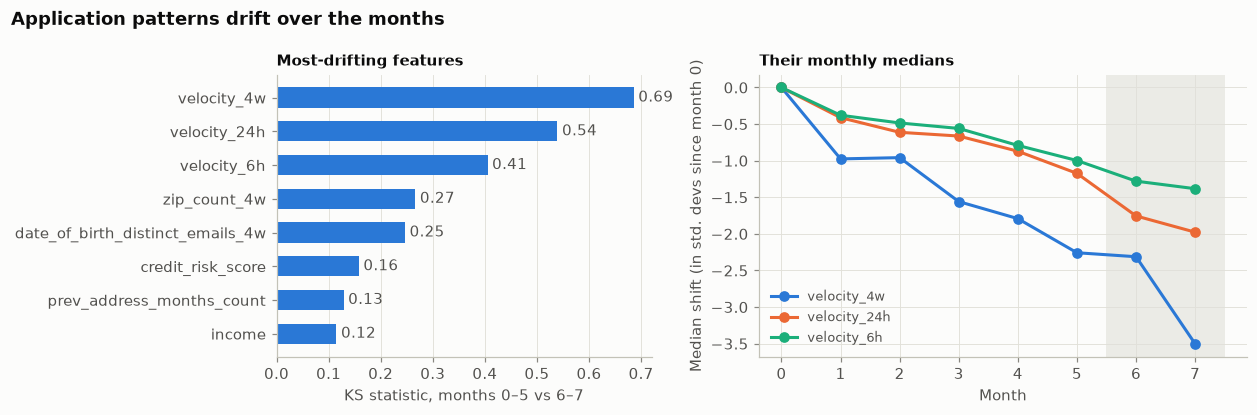

In [8]:
train_p, test_p = df[df.month <= 5], df[df.month >= 6]
drift = pd.Series({c: ks_2samp(train_p[c].dropna(), test_p[c].dropna()).statistic for c in num_cols}).sort_values()
top_drift = drift[-8:]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
bars = axes[0].barh(top_drift.index, top_drift.values, color=SERIES[0], height=0.6)
label_bars(axes[0], bars, fmt="{:.2f}", horizontal=True)
axes[0].set_xlabel("KS statistic, months 0–5 vs 6–7")
axes[0].set_title("Most-drifting features", fontsize=10); axes[0].grid(axis="y", visible=False)
for color, c in zip(SERIES, top_drift.index[::-1][:3]):
    q = df.groupby("month")[c].median()
    axes[1].plot(q.index, (q - q.iloc[0]) / (df[c].std() or 1), marker="o", color=color, label=c)
axes[1].axvspan(5.5, 7.5, color="#e1e0d9", alpha=0.6, lw=0, zorder=0)
axes[1].set_xlabel("Month"); axes[1].set_ylabel("Median shift (in std. devs since month 0)")
axes[1].set_title("Their monthly medians", fontsize=10); axes[1].legend(loc="lower left", fontsize=8.5)
fig.suptitle("Application patterns drift over the months", x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.** The **velocity** features drift by far the most: the number of applications
in the last 6 hours, 24 hours and 4 weeks falls steadily, by up to 3.5 standard deviations
by month 7. They count *traffic*, and traffic falls over the period (section 1). For a
model this is a trap. A fixed velocity value means something different in month 7 than
in month 0, so thresholds and scores learned on the past can shift. Notebook 02 measures
the consequence.

## 6. Takeaways

| Finding | Consequence |
|---|---|
| 1.1 % fraud, rising to 1.5 % in the test months | Evaluate by month. Thresholds tuned on the past may not hold (notebook 02). |
| Business constraint: reject at most 5 % of legitimate applicants | Main metric: **recall at 5 % FPR**, not PR-AUC. |
| Missing values encoded as negatives | Convert to NaN, and add indicators for linear models. |
| Many weak signals; best single KS ≈ 0.3 | Gradient boosting to combine them. |
| Fraud prevalence rises sharply with age (and income) | Expect unequal false-positive rates across age groups (notebook 03). |
| Age correlates with other features | Dropping the age column may not remove age bias. |
| Velocity (traffic) features drift strongly | Watch for threshold drift; monitor these features in production. |

**Next:** [02 · A model at a fixed false-positive rate](02_model_at_fixed_fpr.ipynb)